In [5]:
import matplotlib.pyplot as plt
import numpy as np

In [1]:
import time, json
from tdmclient import ClientAsync

client = ClientAsync()
node = await client.wait_for_node()
await node.lock()

Node 4f38be6d-614b-45ec-9724-7847fdd3c224

In [2]:
TARGET = 100              # motor target (Thymio units)
DURATION = 25             # s
TS = 0.1                  # s
FILE = "run_100_1.json"   # one file per run

def to_signed(v):
    return v - 65536 if v > 32767 else v

def motors(l, r):
    return {"motor.left.target": [l], "motor.right.target": [r]}

await node.wait_for_variables({"motor.left.speed", "motor.right.speed", "prox.ground.reflected"})

data = {"target": TARGET, "t": [], "v_l": [], "v_r": [], "g_l": [], "g_r": []}
try:
    await node.set_variables(motors(TARGET, TARGET))
    t0 = time.time()
    while time.time() - t0 < DURATION:
        g = list(node["prox.ground.reflected"])
        data["t"].append(time.time() - t0)
        data["v_l"].append(to_signed(node["motor.left.speed"]))
        data["v_r"].append(to_signed(node["motor.right.speed"]))
        data["g_l"].append(g[0])
        data["g_r"].append(g[1])
        await client.sleep(TS)
finally:
    await node.set_variables(motors(0, 0))

with open(FILE, "w") as f:
    json.dump(data, f)
print(f"saved {len(data['t'])} samples to {FILE}")

saved 245 samples to run_100_1.json


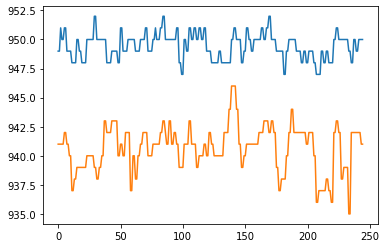

In [7]:
plt.plot(data['g_l'])
plt.plot(data['g_r'])

In [18]:
await node.wait_for_variables({"prox.ground.reflected"})
print(list(node["prox.ground.reflected"]))

[948, 941]


In [27]:
await client.sleep(0.3)
print(list(node["prox.ground.reflected"]))

[273, 218]


In [28]:
await node.unlock()